# 03 | Band-power variability and alpha dynamics

The interquartile range (IQR) is the difference between the 75th and 25th percentiles across epochs. Recordings with the same average power can differ in IQR. Alpha step-size analysis uses the original epoch timing.

**Run in Colab.** See the repository README for Drive access and input paths. Run cells in order and start with notebook 01. Generated files belong in the private working directory. Saved outputs show the original study run.


In [1]:
from pathlib import Path
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, iqr
from IPython.display import display

if 'EEG_WORK' not in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
project = Path('/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab')
work = Path(os.environ.get('EEG_WORK', project/'ورودی‌های خصوصی بازتحلیل'/'derived'))
cache = Path(os.environ.get('EEG_REFERENCE_DIR', work/'inputs'))
raw_dir = Path(os.environ.get('EEG_RAW', '/content/eeg_mcmi_raw'))
for path in [work,cache,raw_dir]:
    path.mkdir(parents=True,exist_ok=True)
os.chdir(work)
def drive_service():
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()
    return build('drive','v3',cache_discovery=False)
def read_existing_drive_file(service,file_id,destination):
    from googleapiclient.http import MediaIoBaseDownload
    temp=destination.with_suffix(destination.suffix+'.part')
    with temp.open('wb') as out:
        reader=MediaIoBaseDownload(out,service.files().get_media(fileId=file_id))
        done=False
        while not done:
            _,done=reader.next_chunk()
    temp.replace(destination)
if not (cache/'scores.xlsx').exists():
    original=Path('/content/drive/MyDrive/MCMI_results.xlsx')
    if original.exists():
        shutil.copyfile(original,cache/'scores.xlsx')
    else:
        read_existing_drive_file(drive_service(),'1EOvKbEfvLAQPTjizNE9DEUR9Ik8xBsiy',cache/'scores.xlsx')
scores = pd.read_excel(cache/'scores.xlsx',index_col=0)
assert scores.index.is_unique
manifest=work/'joint/manifest.json'
ids=sorted(s for s in [Path(v[0]).stem for v in json.loads(manifest.read_text())] if scores.loc[s,'سن']>=18) if manifest.exists() else []
channels='Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz'.split()
def figure(name):
    plt.tight_layout()
    plt.savefig(work/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

Mounted at /content/drive


## Power per epoch

Estimate Welch spectra and divide band power by power from 2 to below 30 Hz. For regions with multiple electrodes, average their power spectra before computing the ratio.


In [2]:
from scipy.signal import welch
from scipy.stats import iqr
bands = {'Delta':(2,4), 'Theta':(4,8), 'Alpha':(8,13), 'LowBeta':(13,20), 'HighBeta':(20,30), 'Beta':(13,30)}
def epoch_features(path):
    with np.load(path) as data:
        names = [c.split('-')[0] for c in data['channels']]
        freq, psd = welch(data['eeg'].astype(float), fs=500, nperseg=500, noverlap=250)
        rows = {}
        regions = {'Global':names,'Occipital':['O1','O2'],'Parietal':['P3','Pz','P4'],
                   'NoFp':[c for c in names if c not in ('Fp1','Fp2')]}
        regions.update({c:[c] for c in names})
        for region, channels in regions.items():
            power = psd[:,[names.index(c) for c in channels]].mean(1)
            total = power[:,(freq>=2)&(freq<30)].sum(1)
            for band,(low,high) in bands.items():
                value = power[:,(freq>=low)&(freq<high)].sum(1)
                rows[f'{region}-{band}'] = 100*value/total
                if band=='Delta':
                    rows[f'{region}-DeltaDB'] = 10*np.log10(value)
        return pd.DataFrame(rows).assign(start=data['start_sample'], subject=path.stem)

assert len(ids)==19, 'Run notebook 01 in full first.'
feature_path=work/'epoch_features.pkl'
if not feature_path.exists():
    pd.concat([epoch_features(p) for p in sorted((work/'out').glob('Subject_*.npz'))],ignore_index=True).to_pickle(feature_path)
epochs=pd.read_pickle(feature_path)
group=epochs[epochs.subject.isin(ids)].groupby('subject',sort=True)
scales=scores.loc[ids,[c for c in scores if c.startswith(('BR_','RAW_')) or c.endswith('_Score')]]
scales=scales.loc[:,scales.nunique()>1]
assert scales.shape==(19,57)

## Separate families of tests

Test six bands against 57 scores for whole-scalp and occipital features, and 19 times that many associations for the channel-level analysis. The CSVs record raw and corrected p-values.


In [3]:
from scipy.stats import false_discovery_control
def ranked_unit(values):
    ranks=rankdata(values,axis=0)
    ranks-=ranks.mean(axis=0)
    return ranks/np.maximum(np.linalg.norm(ranks,axis=0),1e-20)
def scan(features,outcomes,permutations=20000,seed=23):
    outcomes=outcomes.loc[features.index]
    x=ranked_unit(features.to_numpy()); y=ranked_unit(outcomes.to_numpy())
    observed=x.T@y
    hits=np.ones_like(observed); maxima=[]
    rng=np.random.default_rng(seed)
    for start in range(0,permutations,50):
        order=np.array([rng.permutation(len(x)) for _ in range(min(50,permutations-start))])
        sims=np.abs(x.T@y[order])
        hits+=(sims>=np.abs(observed)-1e-12).sum(0)
        maxima.extend(sims.max(axis=(1,2)))
    p=hits/(permutations+1); q=false_discovery_control(p.ravel()).reshape(p.shape)
    pmax=(1+permutations-np.searchsorted(np.sort(maxima),np.abs(observed)-1e-12))/(permutations+1)
    index=pd.MultiIndex.from_product([features.columns,outcomes.columns],names=['feature','score'])
    return pd.DataFrame(dict(rho=observed.ravel(),p=p.ravel(),q=q.ravel(),pmax=pmax.ravel()),index=index)
def partial(x,y,*controls):
    design=np.column_stack([np.ones(len(x)),*[rankdata(z) for z in controls]])
    ranked=rankdata(np.column_stack([x,y]),axis=0)
    residual=ranked-design@np.linalg.lstsq(design,ranked,rcond=None)[0]
    return np.corrcoef(residual.T)[0,1]

for title,regions in [('whole',['Global']),('occipital',['Occipital']),('channels',channels)]:
    names=[f'{r}-{b}' for r in regions for b in bands]
    variability=group[names].quantile(.75)-group[names].quantile(.25)
    result=scan(variability,scales)
    result.to_csv('variability_'+title+'.csv')
    display(result.sort_values('p').head(3))

rho        p         q      pmax
feature      score                                        
Global-Delta BR_8B   0.700399  0.00095  0.324884  0.152842
             RAW_8B  0.654068  0.00230  0.359082  0.312234
             RAW_2A  0.647344  0.00315  0.359082  0.342033

rho         p         q      pmax
feature         score                                         
Occipital-Delta RAW_8B  0.574067  0.009500  0.923354  0.713814
                RAW_6B  0.558456  0.015199  0.923354  0.782311
                RAW_3   0.555216  0.015399  0.923354  0.795860

,,rho,p,q,pmax
feature,score,,,,
F3-Beta,BR_PP,0.666676,0.00190,0.930692,0.907305
T4-Theta,BR_B,0.668178,0.00205,0.930692,0.901605
F3-Beta,RAW_PP,0.665794,0.00215,0.930692,0.909655


## Change between adjacent epochs

Compare the median absolute change between consecutive epochs with 5,000 within-person shuffles that preserve the adjacency mask. Test three resulting measures against 57 scores across participants.


,rho,p,q,pmax
feature,,,,
Step,0.181020,0.455771,0.99514,1.00000
Gap,-0.247804,0.307574,0.99514,1.00000
ReductionPct,-0.310194,0.196736,0.99514,0.99962


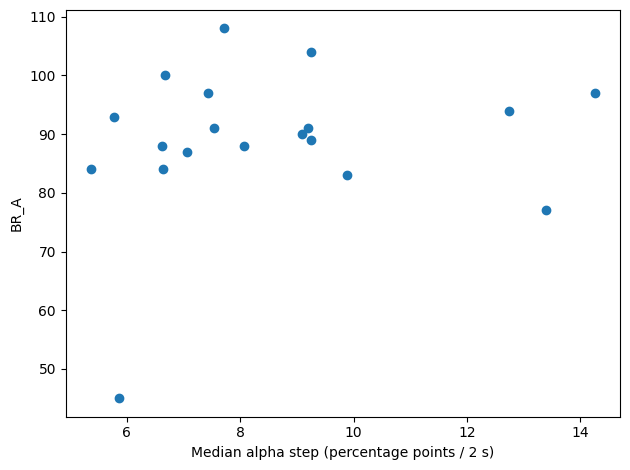

In [4]:
rng=np.random.default_rng(42)
rows=[]
for sid,block in group:
    alpha=block['Occipital-Alpha'].to_numpy(); adjacent=np.diff(block.start)==1000
    step=np.median(np.abs(np.diff(alpha))[adjacent])
    draws=np.array([np.median(np.abs(np.diff(rng.permutation(alpha)))[adjacent]) for _ in range(5000)])
    reference=np.median(draws); gap=reference-step
    rows.append((sid,step,gap,100*gap/reference,(1+sum(draws<=step))/5001))
temporal=pd.DataFrame(rows,columns=['subject','Step','Gap','ReductionPct','p_smooth']).set_index('subject')
temporal['q_smooth']=false_discovery_control(temporal.p_smooth)
temporal.to_csv('alpha_temporal.csv')
tests=scan(temporal[['Step','Gap','ReductionPct']],scales,50000)
tests.to_csv('alpha_171.csv')
display(tests.xs('BR_A',level='score'))
plt.scatter(temporal.Step,scales.loc[temporal.index,'BR_A']);plt.xlabel('Median alpha step (percentage points / 2 s)');plt.ylabel('BR_A');figure('03_alpha_step')